# NCA K5 | XGBoost retrieval baselines

**Two parallel predictive tasks using the same 18 predictors and identical held-out plot-years**

- **Fractional cover (seven FGs):** separately estimate presence (`cover > 0`) and conditional positive cover; combine as `P(present|X) × E[cover|present,X]`. This is a *two-part (hurdle-style) XGBoost predictor*, **not** a fitted zero-inflated beta likelihood.
- **K5 membership (five states):** estimate four additive log-ratios relative to PBG, then invert with softmax. Predicted memberships remain positive and sum to one. This is **not** a Dirichlet likelihood or concentration model.

The experiment isolates the benefit of nonlinear function approximation while holding predictors, targets, and test rows fixed. A grouped 80/20 split is an **initial diagnostic**, not spatially blocked or cross-year validation. No uncertainty intervals are claimed. Outputs are in-sample training diagnostics and held-out predictions, clearly distinguished.

In [1]:
# Optional first-time install in the active notebook kernel:
# %pip install xgboost scikit-learn pandas numpy matplotlib

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score

SEED = 622
rng = np.random.default_rng(SEED)
print("XGBoost:", xgb.__version__)

XGBoost: 3.4.1


In [2]:
# 1. INPUTS AND MODEL CONFIGURATION ---------------------------
MASTER_CSV = Path(r"C:/NCA_DATA/Analysis/NCA_K5_PlotYear_Master/NCA_K5_PlotYear_Master.csv")
OUTPUT_DIR = MASTER_CSV.parent / "XGBoost_Indices18"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FG_COLS = ["EAG_FG", "EF_FG", "PBG_FG", "SHRUB_FG", "BAREGROUND_FG", "LITTER_FG", "BIOCRUST_FG"]
FG_LABELS = ["EAG", "EF", "PBG", "SHRUB", "Bare ground", "Litter", "Biocrust"]
K5_COLS = [f"membership_k5_{k}" for k in range(1, 6)]
K5_LABELS = ["PBG", "ARTR", "SHRUB", "EF", "EAG"]
INDICES = ["ndvi", "ndmi", "ndre", "bsi", "nbr2"]
HARMONIC_FEATURES = [f"{v}_{s}" for v in INDICES for s in ("beta0", "A1_over_beta0", "A2_over_A1")]
FEATURES = HARMONIC_FEATURES + ["Year", "Easting", "Northing"]
assert len(FEATURES) == 18

# Small, fixed baseline hyperparameters, not tuned against the held-out observations.
XGB_PARAMS = dict(n_estimators=350, max_depth=3, learning_rate=0.04,
                  subsample=0.8, colsample_bytree=0.85,
                  reg_lambda=5.0, min_child_weight=5,
                  tree_method="hist", n_jobs=4, random_state=SEED)
TEST_SIZE = 0.20

In [3]:
# 2. READ AND VERIFY COMMON MODELING ROWS --------------------
dat = pd.read_csv(MASTER_CSV, low_memory=False)
needed = ["PlotID", "Year", "Easting", "Northing", *FG_COLS, *K5_COLS, *FEATURES]
missing = sorted(set(needed) - set(dat.columns))
if missing:
    raise ValueError(f"Missing master columns: {missing}")
needed = list(dict.fromkeys(needed))
d = dat.loc[:, needed].copy()
for column in dict.fromkeys([*FG_COLS, *K5_COLS, *FEATURES]):
    d[column] = pd.to_numeric(d[column], errors="coerce")

before = len(d)
d = d.dropna(subset=["PlotID", *FG_COLS, *K5_COLS, *FEATURES]).copy()
d[FG_COLS] = d[FG_COLS] / 100.0  # master records field cover in percent
if not np.isfinite(d[[*FG_COLS, *K5_COLS, *FEATURES]].to_numpy(dtype=float)).all():
    raise ValueError("Non-finite model variables")
if not ((d[FG_COLS] >= 0) & (d[FG_COLS] <= 1)).all().all():
    raise ValueError("Fractional cover outside [0, 1]")
U = d[K5_COLS].to_numpy(float)
if not (np.all(U > 0) and np.all(U < 1) and np.allclose(U.sum(axis=1), 1, atol=1e-5)):
    raise ValueError("K5 membership vectors must be strictly positive and sum to one")

# Unlike zero_inflated_beta(), the two-stage XGBoost model can retain exact 100% cover.
# For strict comparability with the fitted MZIB, set this to True to exclude ALL
# plot-years containing an exact-one FG response, and re-run from this cell.
MATCH_MZIB_EXCLUDE_ONES = False
if MATCH_MZIB_EXCLUDE_ONES:
    d = d.loc[~(d[FG_COLS] == 1).any(axis=1)].copy()

d = d.reset_index(drop=True)
assert d.PlotID.nunique() >= 3
print(f"Master: {before} rows | common eligible: {len(d)} | excluded: {before-len(d)}")
print("Year counts:\n", d.Year.value_counts().sort_index().to_string())
print("Zero counts:\n", (d[FG_COLS] == 0).sum().to_string())
print("Exact-one counts:\n", (d[FG_COLS] == 1).sum().to_string())

Master: 479 rows | common eligible: 479 | excluded: 0
Year counts:
 Year
2016    255
2018    106
2025    118
Zero counts:
 EAG_FG           141
EF_FG            169
PBG_FG           173
SHRUB_FG         283
BAREGROUND_FG      7
LITTER_FG         23
BIOCRUST_FG      107
Exact-one counts:
 EAG_FG           0
EF_FG            0
PBG_FG           0
SHRUB_FG         0
BAREGROUND_FG    2
LITTER_FG        0
BIOCRUST_FG      0


In [4]:
# 3. GROUPED TRAIN/TEST SPLIT -------------------------------
# All years of the same PlotID remain in one partition.
# No scaling is needed for decision trees. No parameter tuning uses held-out rows.
splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
train_idx, test_idx = next(splitter.split(d, groups=d.PlotID.astype(str)))
train = d.iloc[train_idx].copy()
test = d.iloc[test_idx].copy()
assert set(train.PlotID.astype(str)).isdisjoint(set(test.PlotID.astype(str)))
X_train = train[FEATURES]
X_test = test[FEATURES]
print(f"Training: {len(train)} plot-years / {train.PlotID.nunique()} plots")
print(f"Test:     {len(test)} plot-years / {test.PlotID.nunique()} plots")

# Record split explicitly, so future Bayesian and XGBoost comparisons use identical cases.
split_table = pd.concat([train.assign(partition="train"), test.assign(partition="test")])
split_table[["PlotID", "Year", "partition"]].to_csv(OUTPUT_DIR / "split_plotyears.csv", index=False)

Training: 380 plot-years / 346 plots
Test:     99 plot-years / 87 plots


## A. XGBoost for seven fractional-cover groups

For each group, a binary classifier estimates `P(cover > 0 | X)`. A regression trained **only on positive training observations** estimates the expected positive cover. The product estimates unconditional expected cover. Both components depend on X, unlike the intercept-only zero-inflation term in the initial MZIB. To handle boundary covers without arbitrary perturbation, positive cover is regressed on its original `[0, 1]` scale and predictions are clipped to that interval. All reported test statistics use **held-out rows**.

In [5]:
# 4. TRAIN TWO-PART FRACTIONAL COVER MODELS -------------------
fg_models = {}
fg_rows = []
fg_pred = pd.DataFrame({"PlotID": test.PlotID.to_numpy(), "Year": test.Year.to_numpy()}, index=test.index)
fg_importance = []

for col, label in zip(FG_COLS, FG_LABELS):
    y_train = train[col].to_numpy(float)
    y_test = test[col].to_numpy(float)
    occurrence = (y_train > 0).astype(int)

    # If training has a single occurrence class, use its empirical probability.
    classifier = None
    if len(np.unique(occurrence)) == 2:
        classifier = xgb.XGBClassifier(objective="binary:logistic", eval_metric="logloss", **XGB_PARAMS)
        classifier.fit(X_train, occurrence)
        p_present = classifier.predict_proba(X_test)[:, 1]
    else:
        p_present = np.full(len(test), occurrence.mean(), dtype=float)

    # Conditional expected cover among positive observations.
    positive = y_train > 0
    regressor = None
    if positive.sum() >= 2 and np.unique(y_train[positive]).size > 1:
        regressor = xgb.XGBRegressor(objective="reg:squarederror", **XGB_PARAMS)
        regressor.fit(X_train.loc[positive], y_train[positive])
        cover_if_present = np.clip(regressor.predict(X_test), 0, 1)
    else:
        cover_if_present = np.full(len(test), y_train[positive].mean() if positive.any() else 0.0)

    predicted = p_present * cover_if_present
    baseline = np.full(len(test), y_train.mean())
    fg_models[col] = {"presence": classifier, "positive_cover": regressor}
    fg_pred[f"{col}_observed"] = y_test
    fg_pred[f"{col}_predicted"] = predicted
    fg_pred[f"{col}_p_present"] = p_present
    fg_pred[f"{col}_positive_mean"] = cover_if_present
    fg_rows.append(dict(group=label, n_positive_train=int(positive.sum()),
                        n_positive_test=int((y_test>0).sum()),
                        MAE=mean_absolute_error(y_test, predicted),
                        RMSE=np.sqrt(mean_squared_error(y_test, predicted)),
                        Bias=np.mean(predicted-y_test),
                        Baseline_MAE=mean_absolute_error(y_test, baseline),
                        Observed_zero_rate=np.mean(y_test == 0),
                        Mean_predicted_zero_probability=np.mean(1-p_present)))
    for component, model in [("occurrence",classifier),("positive_cover",regressor)]:
        if model is not None:
            for feat, importance in zip(FEATURES, model.feature_importances_):
                fg_importance.append(dict(group=label, component=component, feature=feat, importance=importance))

fg_metrics = pd.DataFrame(fg_rows)
print(fg_metrics.round(3).to_string(index=False))
fg_metrics.to_csv(OUTPUT_DIR / "cover_test_metrics.csv", index=False)
fg_pred.to_csv(OUTPUT_DIR / "cover_test_predictions.csv", index=False)

      group  n_positive_train  n_positive_test   MAE  RMSE   Bias  Baseline_MAE  Observed_zero_rate  Mean_predicted_zero_probability
        EAG               270               68 0.130 0.164  0.025         0.239               0.313                            0.293
         EF               241               69 0.091 0.131  0.003         0.113               0.303                            0.298
        PBG               247               59 0.118 0.171 -0.021         0.145               0.404                            0.380
      SHRUB               157               39 0.065 0.095 -0.006         0.092               0.606                            0.631
Bare ground               375               97 0.093 0.129 -0.014         0.175               0.020                            0.014
     Litter               363               93 0.052 0.067  0.013         0.069               0.061                            0.060
   Biocrust               294               78 0.064 0.092 -0.011    

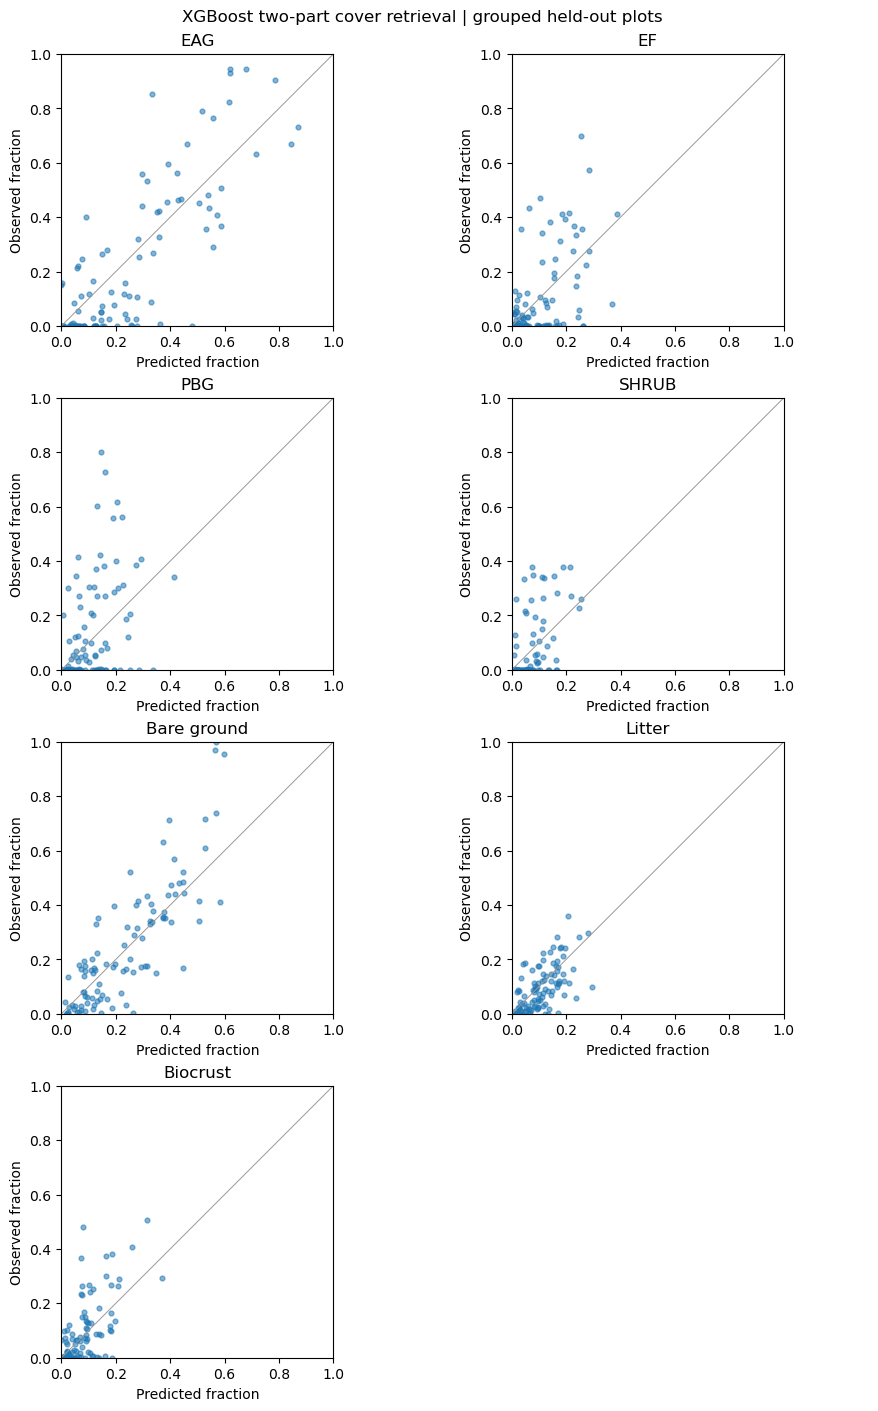

In [6]:
# 5. COVER PREDICTED VS OBSERVED (HELD-OUT) -------------------
fig, axs = plt.subplots(4, 2, figsize=(9, 14), constrained_layout=True)
for ax, col, label in zip(axs.flat, FG_COLS, FG_LABELS):
    ax.scatter(fg_pred[f"{col}_predicted"], fg_pred[f"{col}_observed"], s=12, alpha=.55)
    ax.plot([0,1],[0,1],color="0.6",lw=.7)
    ax.set(xlim=(0,1),ylim=(0,1),title=label)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Predicted fraction")
    ax.set_ylabel("Observed fraction")
axs.flat[-1].axis("off")
fig.suptitle("XGBoost two-part cover retrieval | grouped held-out plots")
plt.savefig(OUTPUT_DIR / "cover_test_scatter.png", dpi=220)
plt.show()

## B. XGBoost for the five-part K5 composition

Fit four independent models for additive log-ratios `log(U_k/U_PBG)`, then reconstruct five positive membership values with softmax. This is the XGBoost analogue of the Dirichlet model's reference-category mean parameterization, **not** a Dirichlet likelihood. Squared error on log-ratios is a different training objective; it does not estimate concentration `phi`. The four predictions are linked through the final inverse transform, not a joint likelihood.

In [7]:
# 6. FIT FOUR LOG-RATIO REGRESSIONS --------------------------
U_train = train[K5_COLS].to_numpy(float)
U_test = test[K5_COLS].to_numpy(float)
Z_train = np.log(U_train[:, 1:] / U_train[:, [0]])

k5_models = []
z_pred = np.zeros((len(test),4))
for k in range(4):
    model = xgb.XGBRegressor(objective="reg:squarederror", **XGB_PARAMS)
    model.fit(X_train, Z_train[:, k])
    z_pred[:, k] = model.predict(X_test)
    k5_models.append(model)

# Stable softmax with reference log-ratio equal to 0
logits = np.column_stack([np.zeros(len(test)), z_pred])
logits -= logits.max(axis=1, keepdims=True)
weights = np.exp(logits)
U_pred = weights / weights.sum(axis=1, keepdims=True)
assert np.isfinite(U_pred).all() and np.all(U_pred > 0)
assert np.allclose(U_pred.sum(axis=1), 1, atol=1e-10)

# Training-only baseline: geometric-center composition in log-ratio coordinates
base_z = Z_train.mean(axis=0)
base_logits = np.r_[0, base_z]
base_logits -= base_logits.max()
base_u = np.exp(base_logits) / np.exp(base_logits).sum()
U_baseline = np.tile(base_u, (len(test),1))

In [8]:
# 7. METRICS: MEMBERSHIPS, HELLINGER, ENTROPY, DOMINANCE -----
def hellinger(A, B):
    return np.sqrt(np.sum((np.sqrt(A)-np.sqrt(B))**2,axis=1) / 2)

def norm_entropy(A):
    A = np.asarray(A)
    return -(A*np.log(A)).sum(axis=1) / np.log(A.shape[1])

k5_rows = []
for k, label in enumerate(K5_LABELS):
    k5_rows.append(dict(state=label, MAE=mean_absolute_error(U_test[:,k],U_pred[:,k]),
                        RMSE=np.sqrt(mean_squared_error(U_test[:,k],U_pred[:,k])),
                        Bias=np.mean(U_pred[:,k]-U_test[:,k])))
k5_metrics = pd.DataFrame(k5_rows)
obs_state = np.argmax(U_test,axis=1)
pred_state = np.argmax(U_pred,axis=1)
summary_metrics = pd.DataFrame([dict(
    n=len(test), mean_hellinger=hellinger(U_test,U_pred).mean(),
    median_hellinger=np.median(hellinger(U_test,U_pred)),
    baseline_mean_hellinger=hellinger(U_test,U_baseline).mean(),
    dominant_state_accuracy=np.mean(obs_state==pred_state),
    majority_state_baseline=np.max(np.bincount(np.argmax(U_train,axis=1), minlength=5))/len(U_train),
    observed_mean_entropy=norm_entropy(U_test).mean(),
    predicted_mean_entropy=norm_entropy(U_pred).mean(),
    observed_endmember_rate=np.mean(U_test.max(axis=1)>0.8),
    predicted_endmember_rate=np.mean(U_pred.max(axis=1)>0.8)
)])
print("Per-state test results:\n",k5_metrics.round(3).to_string(index=False))
print("\nComposition-level test results:\n",summary_metrics.round(3).to_string(index=False))
print("\nObserved vs predicted dominant states (rows observed):")
print(pd.crosstab(pd.Categorical(np.array(K5_LABELS)[obs_state], categories=K5_LABELS),
                  pd.Categorical(np.array(K5_LABELS)[pred_state],categories=K5_LABELS),dropna=False))

k5_pred = pd.DataFrame({"PlotID":test.PlotID.to_numpy(),"Year":test.Year.to_numpy()},index=test.index)
for k, col in enumerate(K5_COLS):
    k5_pred[f"{col}_observed"] = U_test[:,k]
    k5_pred[f"{col}_predicted"] = U_pred[:,k]
k5_pred["hellinger"] = hellinger(U_test,U_pred)
k5_pred["entropy_observed"] = norm_entropy(U_test)
k5_pred["entropy_predicted"] = norm_entropy(U_pred)
k5_pred["dominant_observed"] = np.array(K5_LABELS)[obs_state]
k5_pred["dominant_predicted"] = np.array(K5_LABELS)[pred_state]
k5_pred.to_csv(OUTPUT_DIR / "k5_test_predictions.csv", index=False)
k5_metrics.to_csv(OUTPUT_DIR / "k5_test_metrics.csv", index=False)
summary_metrics.to_csv(OUTPUT_DIR / "k5_test_summary.csv", index=False)

Per-state test results:
 state   MAE  RMSE   Bias
  PBG 0.176 0.279 -0.051
 ARTR 0.094 0.171  0.011
SHRUB 0.165 0.254 -0.006
   EF 0.169 0.262  0.007
  EAG 0.132 0.230  0.039

Composition-level test results:
  n  mean_hellinger  median_hellinger  baseline_mean_hellinger  dominant_state_accuracy  majority_state_baseline  observed_mean_entropy  predicted_mean_entropy  observed_endmember_rate  predicted_endmember_rate
99            0.33             0.329                    0.509                    0.576                    0.287                  0.366                    0.64                    0.626                     0.273

Observed vs predicted dominant states (rows observed):
col_0  PBG  ARTR  SHRUB  EF  EAG
row_0                           
PBG     10     0      3   8    3
ARTR     0     0      1   2    3
SHRUB    1     1     12   5    5
EF       5     0      1  16    0
EAG      3     0      1   0   19


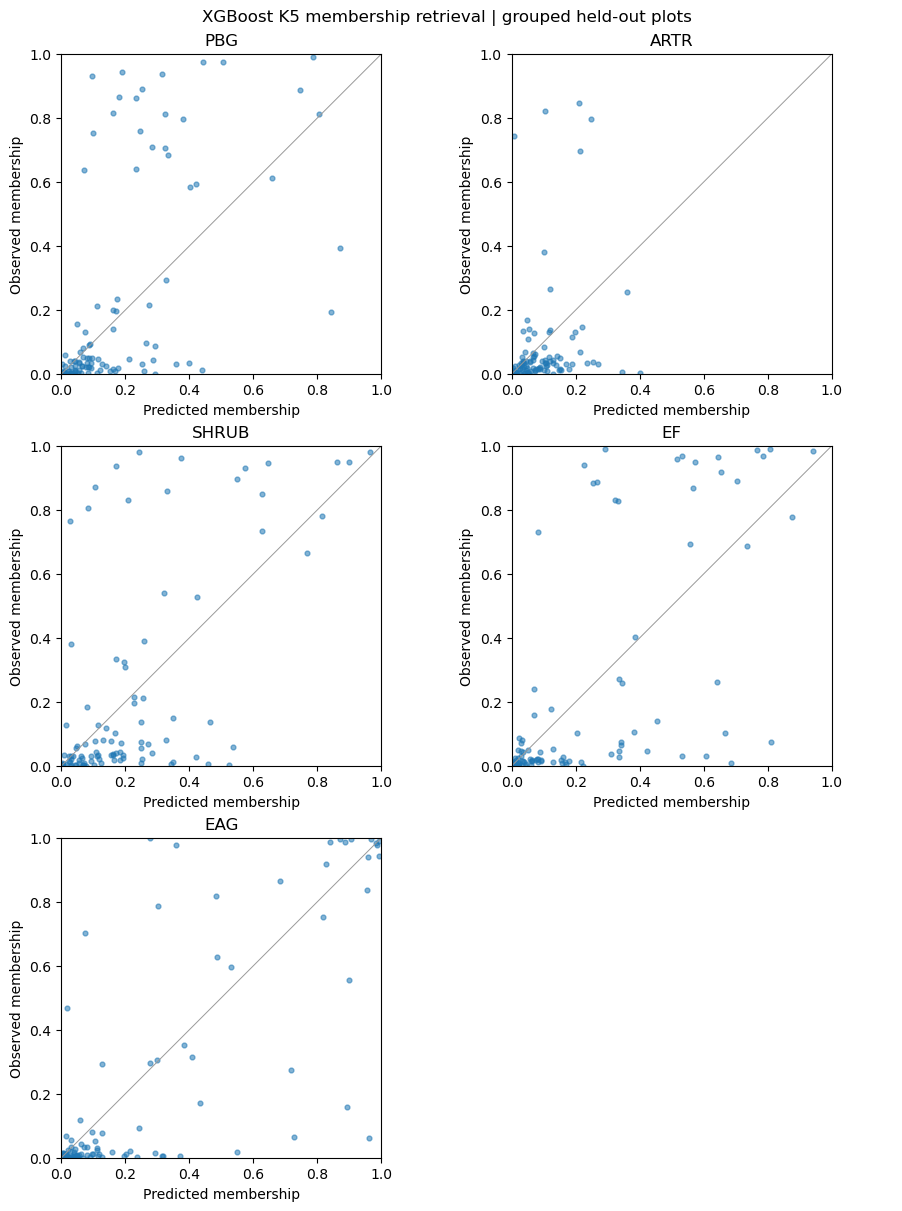

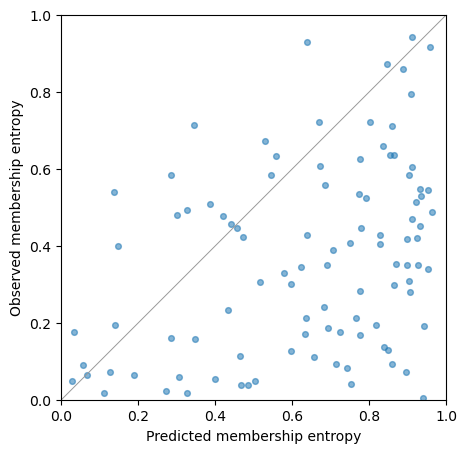

In [9]:
# 8. MEMBERSHIP SCATTER AND ENTROPY (HELD-OUT) ---------------
fig, axs = plt.subplots(3,2,figsize=(9,12),constrained_layout=True)
for k,(ax,label) in enumerate(zip(axs.flat,K5_LABELS)):
    ax.scatter(U_pred[:,k],U_test[:,k],s=12,alpha=.55)
    ax.plot([0,1],[0,1],color="0.6",lw=.7)
    ax.set(xlim=(0,1),ylim=(0,1),title=label,xlabel="Predicted membership",ylabel="Observed membership")
    ax.set_aspect("equal",adjustable="box")
axs.flat[-1].axis("off")
fig.suptitle("XGBoost K5 membership retrieval | grouped held-out plots")
plt.savefig(OUTPUT_DIR / "k5_test_scatter.png",dpi=220)
plt.show()

fig,ax = plt.subplots(figsize=(5,5))
ax.scatter(norm_entropy(U_pred),norm_entropy(U_test),s=17,alpha=.55)
ax.plot([0,1],[0,1],color="0.6",lw=.7)
ax.set(xlim=(0,1),ylim=(0,1),xlabel="Predicted membership entropy",ylabel="Observed membership entropy")
ax.set_aspect("equal", adjustable="box")
plt.savefig(OUTPUT_DIR / "k5_test_entropy.png",dpi=220,bbox_inches="tight")
plt.show()

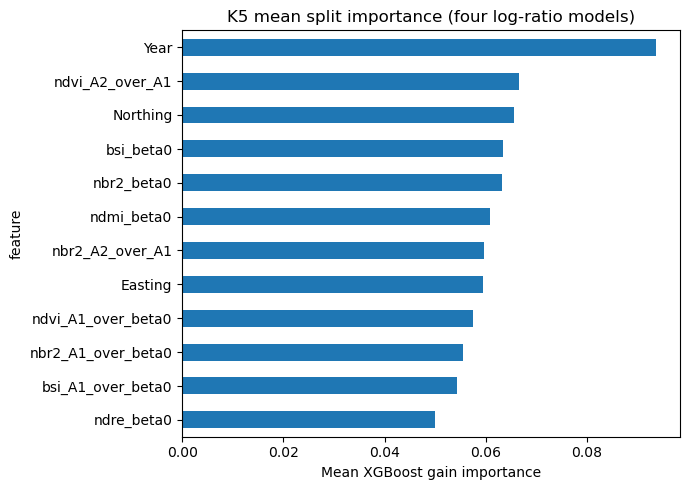

In [10]:
# 9. FEATURE IMPORTANCE — DESCRIPTIVE, NOT CAUSAL ------------
# Split-gain importance can be redistributed among correlated features.
# It does not establish which features are uniquely necessary for prediction.
importance_rows = []
for k,model in enumerate(k5_models):
    for feat,importance in zip(FEATURES,model.feature_importances_):
        importance_rows.append(dict(state=K5_LABELS[k+1],feature=feat,importance=importance))
imp = pd.DataFrame(importance_rows)
imp.groupby("feature").importance.mean().sort_values().tail(12).plot.barh(figsize=(7,5),title="K5 mean split importance (four log-ratio models)")
plt.xlabel("Mean XGBoost gain importance")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "k5_feature_importance.png",dpi=220)
plt.show()
imp.to_csv(OUTPUT_DIR / "k5_feature_importance.csv",index=False)
pd.DataFrame(fg_importance).to_csv(OUTPUT_DIR / "cover_feature_importance.csv",index=False)

## Interpreting this first experiment

- Compare each task against its **own baseline**; Hellinger distance and fractional-cover MAE are not directly comparable measures of task difficulty.
- A low Hellinger distance or high dominant-state agreement is evidence about predictions on the held-out *plots*, not necessarily unseen years or distant geographic regions.
- All model choices above are fixed in advance; do not select hyperparameters using these test rows and then describe them as untouched evaluation data.
- The compositional log-ratio objective weights errors differently from a Dirichlet likelihood. The two-part cover predictor differs from ZIB because occurrence depends on the predictors. This makes the experiment a test of flexible nonlinear retrieval, not a pure Bayesian-versus-XGBoost algorithm comparison.
- Next rigorous step: spatially blocked and leave-one-year-out validation; then compare against Bayesian models using exactly the same folds and response definitions. For 2026, prefer reserving the year as a temporal test if it was not used to learn the K5 definition or model settings.

Baseline predictors: 18
Expanded predictors: 48
Training observations: 380
Held-out observations: 99

FRACTIONAL COVER COMPARISON
      Group  MAE_18  MAE_48  RMSE_18  RMSE_48  MAE_improvement
        EAG  0.1296  0.1343   0.1636   0.1839          -0.0047
         EF  0.0910  0.0851   0.1308   0.1249           0.0059
        PBG  0.1179  0.1087   0.1707   0.1625           0.0092
      SHRUB  0.0646  0.0623   0.0954   0.0921           0.0023
Bare ground  0.0930  0.0946   0.1286   0.1356          -0.0016
     Litter  0.0521  0.0524   0.0674   0.0689          -0.0003
   Biocrust  0.0640  0.0613   0.0923   0.0925           0.0027

K5 MEMBERSHIP COMPARISON
          Model  Mean_Hellinger  Dominant_state_accuracy  Entropy_MAE
      Indices18          0.3302                   0.5758       0.3305
FullHarmonics48          0.3515                   0.5253       0.2994


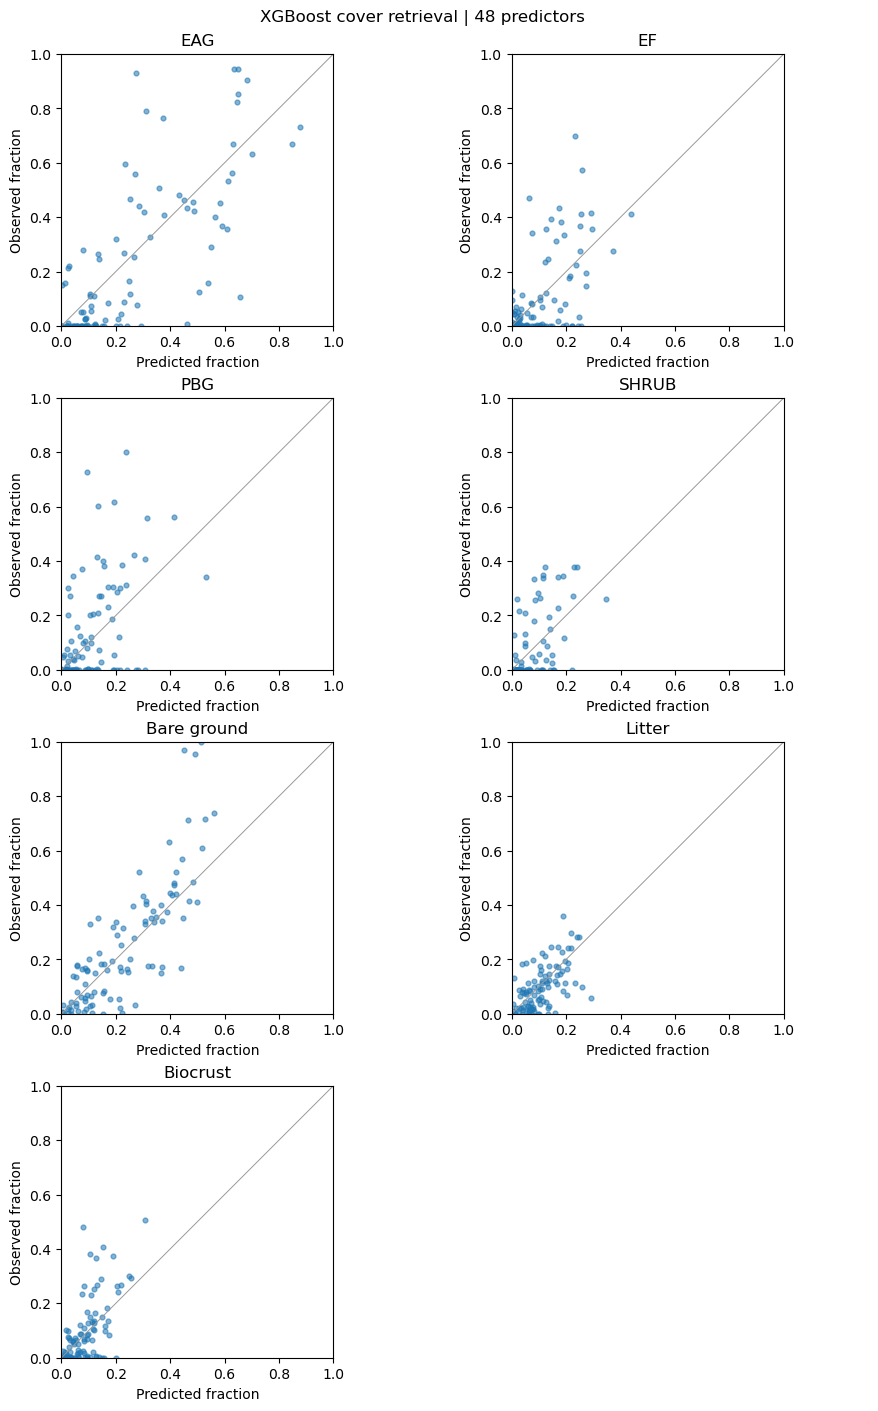

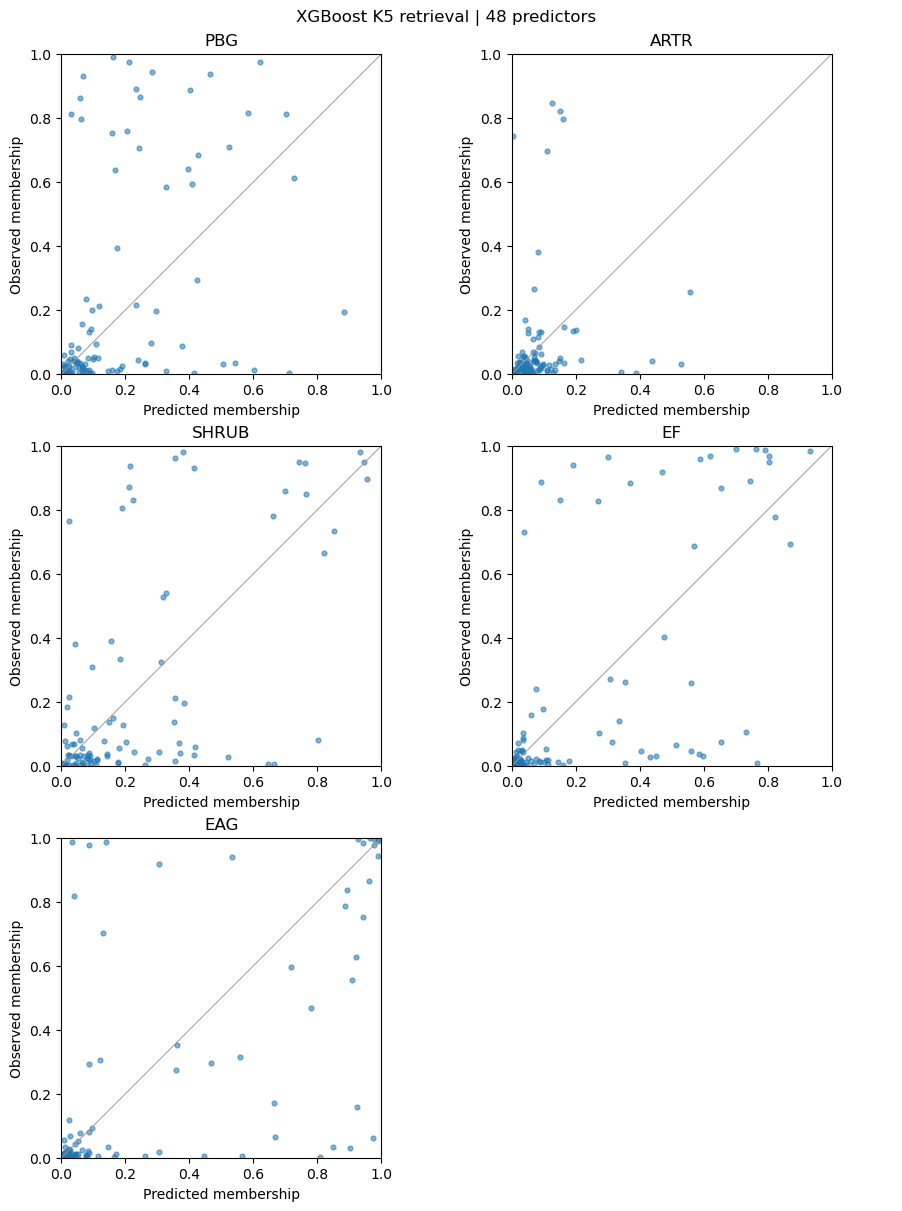


Saved comparisons to: C:\NCA_DATA\Analysis\NCA_K5_PlotYear_Master\XGBoost_Indices18\FullHarmonics48


In [11]:

# ============================================================
# 10. XGBOOST — FULL 48-FEATURE HARMONIC REPRESENTATION
# Same responses, model parameters, and held-out PlotIDs
# ============================================================

# 1. EXPAND PREDICTOR SET ------------------------------------

BANDS = [
    "b2", "b3", "b4", "b5", "b6",
    "b7", "b8", "b8a", "b11", "b12"
]

BAND_FEATURES = [
    f"{band}_{suffix}"
    for band in BANDS
    for suffix in ("beta0", "A1_over_beta0", "A2_over_A1")
]

FULL_FEATURES = [
    *BAND_FEATURES,
    *HARMONIC_FEATURES,
    "Year", "Easting", "Northing"
]

assert len(FULL_FEATURES) == 48
assert set(FEATURES).issubset(FULL_FEATURES)

missing = sorted(set(FULL_FEATURES) - set(dat.columns))
if missing:
    raise ValueError(f"Missing full harmonic features: {missing}")

# Preserve the existing grouped train/test split
# and observation ordering.
keys = ["PlotID", "Year"]

if dat.duplicated(keys).any():
    raise ValueError("Duplicate PlotID-Year keys in master data.")

lookup = dat.set_index(keys)[BAND_FEATURES].apply(
    pd.to_numeric, errors="coerce"
)

train48 = train.join(lookup, on=keys)
test48 = test.join(lookup, on=keys)

for name, frame in [("train", train48), ("test", test48)]:
    if not np.isfinite(
        frame[FULL_FEATURES].to_numpy(dtype=float)
    ).all():
        raise ValueError(
            f"Missing or nonfinite full features in {name}. "
            "Resolve eligibility before comparing representations."
        )

Xtr48 = train48[FULL_FEATURES]
Xte48 = test48[FULL_FEATURES]

OUT48 = OUTPUT_DIR / "FullHarmonics48"
OUT48.mkdir(parents=True, exist_ok=True)

print("Baseline predictors:", len(FEATURES))
print("Expanded predictors:", len(FULL_FEATURES))
print("Training observations:", len(train48))
print("Held-out observations:", len(test48))


# 2. SEVEN TWO-PART COVER MODELS ------------------------------

cover48 = {}
cover_metrics48 = []

for col, label in zip(FG_COLS, FG_LABELS):

    ytr = train48[col].to_numpy(float)
    yte = test48[col].to_numpy(float)

    present = (ytr > 0).astype(int)

    # Occurrence model
    if np.unique(present).size == 2:
        clf = xgb.XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            **XGB_PARAMS
        )
        clf.fit(Xtr48, present)
        p_present = clf.predict_proba(Xte48)[:, 1]
    else:
        p_present = np.full(len(test48), present.mean())

    # Positive-cover model
    positive = ytr > 0

    if positive.sum() >= 2 and np.unique(ytr[positive]).size > 1:
        reg = xgb.XGBRegressor(
            objective="reg:squarederror",
            **XGB_PARAMS
        )
        reg.fit(Xtr48.loc[positive], ytr[positive])
        positive_cover = np.clip(reg.predict(Xte48), 0, 1)
    else:
        positive_cover = np.full(
            len(test48),
            ytr[positive].mean() if positive.any() else 0
        )

    pred = p_present * positive_cover
    cover48[col] = pred

    baseline_pred = fg_pred.loc[
        test48.index, f"{col}_predicted"
    ].to_numpy()

    cover_metrics48.append({
        "Group": label,
        "MAE_18": mean_absolute_error(yte, baseline_pred),
        "MAE_48": mean_absolute_error(yte, pred),
        "RMSE_18": np.sqrt(mean_squared_error(yte, baseline_pred)),
        "RMSE_48": np.sqrt(mean_squared_error(yte, pred))
    })

cover_comparison = pd.DataFrame(cover_metrics48)

cover_comparison["MAE_improvement"] = (
    cover_comparison["MAE_18"] - cover_comparison["MAE_48"]
)

print("\nFRACTIONAL COVER COMPARISON")
print(cover_comparison.round(4).to_string(index=False))


# 3. FIVE-PART K5 MEMBERSHIP MODEL ----------------------------

Utr = train48[K5_COLS].to_numpy(float)
Ute = test48[K5_COLS].to_numpy(float)

# Four additive log-ratios relative to K1 (PBG)
Ztr = np.log(Utr[:, 1:] / Utr[:, [0]])

Zpred48 = np.column_stack([
    (
        lambda model: (
            model.fit(Xtr48, Ztr[:, k]),
            model.predict(Xte48)
        )[1]
    )(
        xgb.XGBRegressor(
            objective="reg:squarederror",
            **XGB_PARAMS
        )
    )
    for k in range(4)
])

# Reconstruct positive five-part composition
logits = np.column_stack([
    np.zeros(len(test48)), Zpred48
])

logits -= logits.max(axis=1, keepdims=True)

weights = np.exp(logits)
U48 = weights / weights.sum(axis=1, keepdims=True)

assert np.allclose(U48.sum(axis=1), 1)

# Original 18-feature predictions on identical test plots
U18 = np.column_stack([
    k5_pred.loc[
        test48.index, f"{col}_predicted"
    ].to_numpy()
    for col in K5_COLS
])

k5_comparison = pd.DataFrame({
    "Model": ["Indices18", "FullHarmonics48"],
    "Mean_Hellinger": [
        hellinger(Ute, U18).mean(),
        hellinger(Ute, U48).mean()
    ],
    "Dominant_state_accuracy": [
        np.mean(Ute.argmax(axis=1) == U18.argmax(axis=1)),
        np.mean(Ute.argmax(axis=1) == U48.argmax(axis=1))
    ],
    "Entropy_MAE": [
        np.mean(abs(norm_entropy(Ute) - norm_entropy(U18))),
        np.mean(abs(norm_entropy(Ute) - norm_entropy(U48)))
    ]
})

print("\nK5 MEMBERSHIP COMPARISON")
print(k5_comparison.round(4).to_string(index=False))


# 4. VISUALIZE FULL-REPRESENTATION PREDICTIONS ----------------

fig, axs = plt.subplots(
    4, 2, figsize=(9, 14), constrained_layout=True
)

for ax, col, label in zip(axs.flat, FG_COLS, FG_LABELS):
    ax.scatter(
        cover48[col], test48[col],
        s=12, alpha=0.55
    )
    ax.plot([0, 1], [0, 1], color="0.6", lw=0.7)
    ax.set(
        xlim=(0, 1), ylim=(0, 1),
        title=label,
        xlabel="Predicted fraction",
        ylabel="Observed fraction"
    )
    ax.set_aspect("equal", adjustable="box")

axs.flat[-1].axis("off")
fig.suptitle("XGBoost cover retrieval | 48 predictors")
plt.savefig(OUT48 / "cover_scatter48.png", dpi=220)
plt.show()


fig, axs = plt.subplots(
    3, 2, figsize=(9, 12), constrained_layout=True
)

for k, (ax, label) in enumerate(zip(axs.flat, K5_LABELS)):
    ax.scatter(
        U48[:, k], Ute[:, k],
        s=12, alpha=0.55
    )
    ax.plot([0, 1], [0, 1], color="0.6", lw=0.7)
    ax.set(
        xlim=(0, 1), ylim=(0, 1),
        title=label,
        xlabel="Predicted membership",
        ylabel="Observed membership"
    )
    ax.set_aspect("equal", adjustable="box")

axs.flat[-1].axis("off")
fig.suptitle("XGBoost K5 retrieval | 48 predictors")
plt.savefig(OUT48 / "k5_scatter48.png", dpi=220)
plt.show()


# 5. SAVE COMPARISONS -----------------------------------------

cover_comparison.to_csv(
    OUT48 / "cover_18_vs_48.csv", index=False
)

k5_comparison.to_csv(
    OUT48 / "k5_18_vs_48.csv", index=False
)

print("\nSaved comparisons to:", OUT48)


Training observations: 380
Held-out observations: 99
Phase predictors: ['ndvi_k2_p1_sin', 'ndvi_k2_p1_cos', 'ndvi_k2_p2_sin', 'ndvi_k2_p2_cos']

COVER — PHASE EXPERIMENT
      Group  MAE_18  MAE_22  Improvement
        EAG  0.1296  0.1268       0.0028
         EF  0.0910  0.0850       0.0059
        PBG  0.1179  0.1184      -0.0005
      SHRUB  0.0646  0.0609       0.0037
Bare ground  0.0930  0.0930      -0.0000
     Litter  0.0521  0.0559      -0.0038
   Biocrust  0.0640  0.0618       0.0022

K5 — PHASE EXPERIMENT
   Representation  Hellinger  Dominant_accuracy  Entropy_MAE
        Indices18     0.3302             0.5758       0.3305
Indices18 + phase     0.3266             0.6263       0.3124


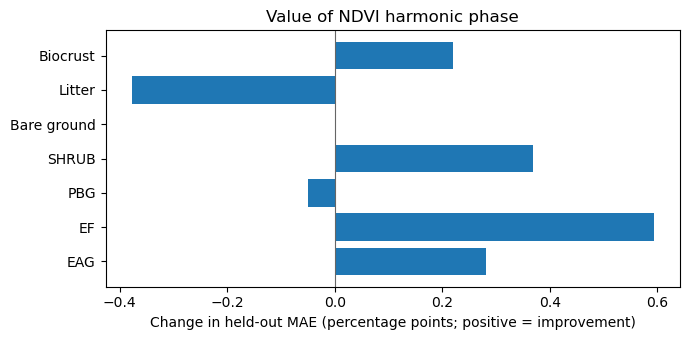

In [12]:

# ============================================================
# XGBOOST — NDVI HARMONIC PHASE EXPERIMENT
# 18 predictors vs. 22 predictors
# Same grouped train/test partition and hyperparameters
# ============================================================

PHASE_COLS = ["ndvi_k2_p1", "ndvi_k2_p2"]
KEYS = ["PlotID", "Year"]

# 1. PREPARE PHASE FEATURES ----------------------------------

assert all(c in dat.columns for c in PHASE_COLS)
assert not dat.duplicated(KEYS).any()

phase = dat.set_index(KEYS)[PHASE_COLS].apply(
    pd.to_numeric, errors="coerce"
)

train_phase = train.join(phase, on=KEYS)
test_phase = test.join(phase, on=KEYS)

# Verify that phase is expressed in radians.
# If these are DOY or degrees, convert before using sin/cos.
values = pd.concat([
    train_phase[PHASE_COLS],
    test_phase[PHASE_COLS]
]).to_numpy(dtype=float)

finite_values = values[np.isfinite(values)]

assert len(finite_values) > 0
assert np.max(np.abs(finite_values)) <= 2 * np.pi + 1e-4, (
    "Phase values do not appear to be radians. "
    "Inspect the original phase calculation."
)

PHASE_FEATURES = []

for col in PHASE_COLS:
    sin_col = f"{col}_sin"
    cos_col = f"{col}_cos"

    for frame in (train_phase, test_phase):
        frame[sin_col] = np.sin(frame[col])
        frame[cos_col] = np.cos(frame[col])

    PHASE_FEATURES += [sin_col, cos_col]

# Restrict both representations to identical eligible rows.
train_phase = train_phase.dropna(subset=PHASE_FEATURES).copy()
test_phase = test_phase.dropna(subset=PHASE_FEATURES).copy()

FEATURES_PHASE = FEATURES + PHASE_FEATURES

assert len(FEATURES_PHASE) == 22

Xtr18 = train_phase[FEATURES]
Xte18 = test_phase[FEATURES]

Xtr22 = train_phase[FEATURES_PHASE]
Xte22 = test_phase[FEATURES_PHASE]

print("Training observations:", len(train_phase))
print("Held-out observations:", len(test_phase))
print("Phase predictors:", PHASE_FEATURES)


# 2. FIT BOTH RESPONSE TYPES ---------------------------------

def fit_phase_experiment(Xtr, Xte):

    # A. Two-stage functional-group cover
    cover_pred = {}

    for col in FG_COLS:
        y = train_phase[col].to_numpy(float)
        present = (y > 0).astype(int)

        if np.unique(present).size == 2:
            clf = xgb.XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",
                **XGB_PARAMS
            )
            clf.fit(Xtr, present)
            p = clf.predict_proba(Xte)[:, 1]
        else:
            p = np.full(len(Xte), present.mean())

        positive = y > 0

        if positive.sum() >= 2 and np.unique(y[positive]).size > 1:
            reg = xgb.XGBRegressor(
                objective="reg:squarederror",
                **XGB_PARAMS
            )
            reg.fit(Xtr.loc[positive], y[positive])
            mu = np.clip(reg.predict(Xte), 0, 1)
        else:
            mu = np.full(
                len(Xte),
                y[positive].mean() if positive.any() else 0
            )

        cover_pred[col] = p * mu

    # B. Four log-ratio K5 regressions
    Utr = train_phase[K5_COLS].to_numpy(float)

    Ztr = np.log(Utr[:, 1:] / Utr[:, [0]])

    Zpred = np.zeros((len(Xte), 4))

    for k in range(4):
        model = xgb.XGBRegressor(
            objective="reg:squarederror",
            **XGB_PARAMS
        )
        model.fit(Xtr, Ztr[:, k])
        Zpred[:, k] = model.predict(Xte)

    logits = np.column_stack([
        np.zeros(len(Xte)), Zpred
    ])
    logits -= logits.max(axis=1, keepdims=True)

    weights = np.exp(logits)
    U_pred = weights / weights.sum(axis=1, keepdims=True)

    return cover_pred, U_pred


cover18, membership18 = fit_phase_experiment(Xtr18, Xte18)
cover22, membership22 = fit_phase_experiment(Xtr22, Xte22)


# 3. FRACTIONAL-COVER COMPARISON ------------------------------

cover_rows = []

for col, label in zip(FG_COLS, FG_LABELS):
    y = test_phase[col].to_numpy(float)

    mae18 = mean_absolute_error(y, cover18[col])
    mae22 = mean_absolute_error(y, cover22[col])

    cover_rows.append({
        "Group": label,
        "MAE_18": mae18,
        "MAE_22": mae22,
        "Improvement": mae18 - mae22
    })

phase_cover_results = pd.DataFrame(cover_rows)

print("\nCOVER — PHASE EXPERIMENT")
print(phase_cover_results.round(4).to_string(index=False))


# 4. K5 MEMBERSHIP COMPARISON ---------------------------------

Utest = test_phase[K5_COLS].to_numpy(float)

def k5_metrics(U_pred):
    return {
        "Hellinger": hellinger(Utest, U_pred).mean(),
        "Dominant_accuracy": np.mean(
            Utest.argmax(axis=1) == U_pred.argmax(axis=1)
        ),
        "Entropy_MAE": np.mean(
            np.abs(norm_entropy(Utest) - norm_entropy(U_pred))
        )
    }

phase_k5_results = pd.DataFrame([
    {"Representation": "Indices18", **k5_metrics(membership18)},
    {"Representation": "Indices18 + phase", **k5_metrics(membership22)}
])

print("\nK5 — PHASE EXPERIMENT")
print(phase_k5_results.round(4).to_string(index=False))


# 5. VISUALIZE CHANGES IN COVER MAE ---------------------------

fig, ax = plt.subplots(figsize=(7, 3.5))

ax.barh(
    phase_cover_results["Group"],
    phase_cover_results["Improvement"] * 100
)

ax.axvline(0, color="0.4", lw=0.8)

ax.set_xlabel(
    "Change in held-out MAE (percentage points; positive = improvement)"
)
ax.set_title("Value of NDVI harmonic phase")

plt.tight_layout()
plt.show()


Dominant-state accuracy: 0.6262626262626263
Balanced accuracy: 0.5613965744400526
Majority-class baseline: 0.23232323232323232

Classification report:
              precision    recall  f1-score   support

         PBG       0.60      0.38      0.46        24
        ARTR       0.25      0.17      0.20         6
       SHRUB       0.68      0.62      0.65        24
          EF       0.53      0.73      0.62        22
         EAG       0.75      0.91      0.82        23

    accuracy                           0.63        99
   macro avg       0.56      0.56      0.55        99
weighted avg       0.62      0.63      0.61        99



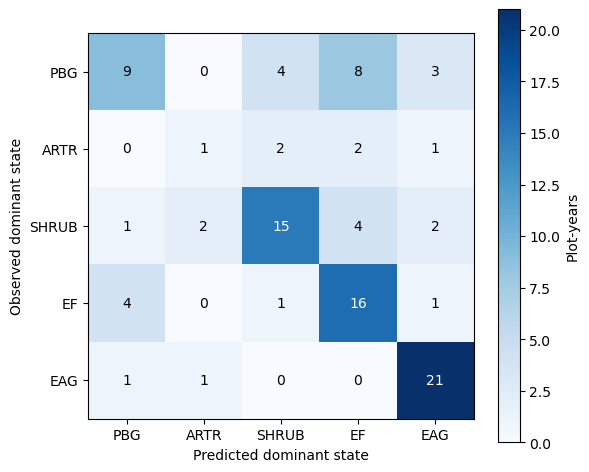


Accuracy by observed membership dominance:
               n  accuracy
dominance                 
(0.199, 0.4]   5  0.200000
(0.4, 0.6]     8  0.625000
(0.6, 0.8]    24  0.500000
(0.8, 1.0]    62  0.709677


In [13]:

# ============================================================
# XGBOOST — DOMINANT K5 STATE CLASSIFICATION
# Uses existing train/test split and 18-feature representation
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)
from sklearn.dummy import DummyClassifier

# 1. DEFINE DOMINANT STATE ------------------------------------

U_train = train[K5_COLS].to_numpy(dtype=float)
U_test = test[K5_COLS].to_numpy(dtype=float)

y_train = U_train.argmax(axis=1)
y_test = U_test.argmax(axis=1)

# 2. FIT MULTICLASS CLASSIFIER -------------------------------

state_clf = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=5,
    eval_metric="mlogloss",
    **XGB_PARAMS
)

state_clf.fit(
    train[FEATURES],
    y_train
)

y_pred = state_clf.predict(test[FEATURES]).astype(int)
p_pred = state_clf.predict_proba(test[FEATURES])

# 3. PERFORMANCE ----------------------------------------------

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(train[FEATURES], y_train)
y_baseline = baseline.predict(test[FEATURES])

print("Dominant-state accuracy:",
      accuracy_score(y_test, y_pred))

print("Balanced accuracy:",
      balanced_accuracy_score(y_test, y_pred))

print("Majority-class baseline:",
      accuracy_score(y_test, y_baseline))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(5),
        target_names=K5_LABELS,
        zero_division=0
    )
)

# 4. CONFUSION MATRIX -----------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(5)
)

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(5), K5_LABELS)
ax.set_yticks(range(5), K5_LABELS)

ax.set_xlabel("Predicted dominant state")
ax.set_ylabel("Observed dominant state")

for i in range(5):
    for j in range(5):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > cm.max()/2 else "black"
        )

fig.colorbar(im, ax=ax, label="Plot-years")
plt.tight_layout()
plt.show()


# 5. CLASSIFICATION VS MEMBERSHIP AMBIGUITY -------------------

observed_max = U_test.max(axis=1)

confidence_df = pd.DataFrame({
    "max_membership": observed_max,
    "correct": y_pred == y_test
})

confidence_df["dominance"] = pd.cut(
    confidence_df["max_membership"],
    bins=[0.2, 0.4, 0.6, 0.8, 1.0],
    include_lowest=True
)

dominance_accuracy = (
    confidence_df
    .groupby("dominance", observed=False)
    .agg(
        n=("correct", "size"),
        accuracy=("correct", "mean")
    )
)

print("\nAccuracy by observed membership dominance:")
print(dominance_accuracy)
